# 01 · Análise exploratória das avaliações de clientes

**Tech Challenge – Fase 4 · Voice of Customer Intelligence com RAG**

Este notebook é a primeira etapa do projeto. Antes de construir a base de conhecimento do RAG, precisamos entender **o que existe nos comentários dos clientes**: quantos têm texto, como são escritos, onde há ruído, duplicatas e valores ausentes, e quais metadados ajudam a explicar a insatisfação.

Cada seção termina com uma **implicação para o projeto**. A seção final reúne essas implicações nas decisões de preparo da base, que serão implementadas na etapa seguinte.

| Seção | Pergunta |
| --- | --- |
| 1 | Quais tabelas usamos e como elas se relacionam? |
| 2 | Quem escreve comentários, e com que nota? |
| 3 | Qual o tamanho dos comentários? |
| 4 | Qual a qualidade do texto? |
| 5 | Como são os comentários reais? |
| 6 | Há duplicatas ou problemas de integridade? |
| 7 | Quais valores estão ausentes nas tabelas de apoio? |
| 8 | Quais metadados explicam a insatisfação? |
| 9 | O que decidimos a partir disso? |

### Principais achados

1. **Só 43% das avaliações têm texto, e as negativas comentam muito mais.** Cerca de 77% das notas 1 têm texto, contra 38% das notas 5. A base de texto é rica justamente em motivos de insatisfação.
2. **Comentários são curtos** (mediana de 53 caracteres) e **truncados em cerca de 200 caracteres** na origem. Uma avaliação = um documento, sem *chunking*.
3. **Cerca de 1 em cada 5 comentários é cópia de outro** ("muito bom", "ótimo"). São clientes distintos, mas as cópias poluiriam o top-k da busca vetorial.
4. **A entrega é o metadado que mais separa satisfeitos de insatisfeitos.** Entregas no prazo têm 9% de avaliações negativas. Atrasadas, 62%. Não entregues, 78%.
5. **Pedidos sem itens** (indisponíveis ou cancelados) têm 81% de negativas e se escondem atrás de "categoria desconhecida" se não forem tratados à parte.
6. **Os nomes de lojas foram anonimizados** com casas de *Game of Thrones* ("lannister", "stark"…), citadas em cerca de 2 mil comentários.

In [1]:
import re
import unicodedata
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd
from IPython.display import Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", "{:,.2f}".format)

# ---- Identidade visual dos gráficos -------------------------------------------
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
PRIMARY = "#2a78d6"  # medida única
# Nota 1→5 é polaridade (insatisfeito ↔ satisfeito): escala divergente
# vermelho ↔ cinza ↔ azul, com o neutro (nota 3) no centro.
SCORE_COLORS = {1: "#e34948", 2: "#f09a99", 3: "#d3d2ca", 4: "#86b6ef", 5: "#2a78d6"}

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.family": ["Segoe UI", "DejaVu Sans", "sans-serif"], "font.size": 10,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 24,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2, "ytick.left": False,
})

def pct(x, total):
    return f"{x / total:.1%}".replace(".", ",")

def num(x):
    return f"{x:,.0f}".replace(",", ".")

def subtitle(ax, text):
    ax.text(0, 1.015, text, transform=ax.transAxes, color=INK_2, fontsize=9.5, va="bottom")

LABEL_BOX = dict(boxstyle="square,pad=0.15", facecolor=SURFACE, edgecolor="none")

def label_bars(ax, bars, labels, inside=False):
    for bar, label in zip(bars, labels):
        ax.annotate(label, (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    xytext=(0, 4), textcoords="offset points", ha="center", va="bottom",
                    color=INK, fontsize=9)

## 1. Tabelas e relacionamentos

O foco do desafio são os comentários em `order_reviews`. As demais tabelas entram como **fontes de metadados** (entrega, categoria, período), que mais adiante servem para filtrar e contextualizar a recuperação.

```
order_reviews ──order_id──► orders ──order_id──► order_items ──product_id──► products ──► category_translation
  nota, título,               status, datas de        produto, vendedor,       categoria       nome em inglês
  comentário                  compra e entrega         preço, frete
```

In [2]:
reviews = pd.read_csv(RAW / "olist_order_reviews_dataset.csv",
                      parse_dates=["review_creation_date", "review_answer_timestamp"])
orders = pd.read_csv(RAW / "olist_orders_dataset.csv",
                     parse_dates=["order_purchase_timestamp", "order_approved_at",
                                  "order_delivered_carrier_date", "order_delivered_customer_date",
                                  "order_estimated_delivery_date"])
items = pd.read_csv(RAW / "olist_order_items_dataset.csv")
products = pd.read_csv(RAW / "olist_products_dataset.csv")
translation = pd.read_csv(RAW / "product_category_name_translation.csv", encoding="utf-8-sig")

tables = {"order_reviews": reviews, "orders": orders, "order_items": items,
          "products": products, "category_translation": translation}
pd.DataFrame({
    "linhas": {n: len(t) for n, t in tables.items()},
    "colunas": {n: t.shape[1] for n, t in tables.items()},
    "células ausentes (%)": {n: t.isna().mean().mean() * 100 for n, t in tables.items()},
})

,linhas,colunas,células ausentes (%)
order_reviews,99224,7,21.01
orders,99441,8,0.62
order_items,112650,7,0.00
products,32951,9,0.83
category_translation,71,2,0.00


In [3]:
reviews.isna().mean().mul(100).round(1).rename("% ausente").to_frame()

,% ausente
review_id,0.00
order_id,0.00
review_score,0.00
review_comment_title,88.30
review_comment_message,58.70
review_creation_date,0.00
review_answer_timestamp,0.00


Em `order_reviews`, **só a nota é sempre preenchida**. Título e comentário são opcionais e estão ausentes na maior parte das linhas. Por isso, o número real de documentos do RAG é bem menor que as 99 mil avaliações. A próxima seção mede esse número.

## 2. Quem escreve comentários, e com que nota?

In [4]:
has_title = reviews["review_comment_title"].fillna("").str.strip() != ""
has_msg = reviews["review_comment_message"].fillna("").str.strip() != ""
reviews["has_text"] = has_title | has_msg

combo = pd.Series({
    "título e comentário": (has_title & has_msg).sum(),
    "só comentário": (~has_title & has_msg).sum(),
    "só título": (has_title & ~has_msg).sum(),
    "nenhum texto": (~has_title & ~has_msg).sum(),
})
combo.to_frame("avaliações").assign(**{"%": combo / len(reviews) * 100})

,avaliações,%
título e comentário,9829,9.91
só comentário,31121,31.36
só título,1737,1.75
nenhum texto,56537,56.98


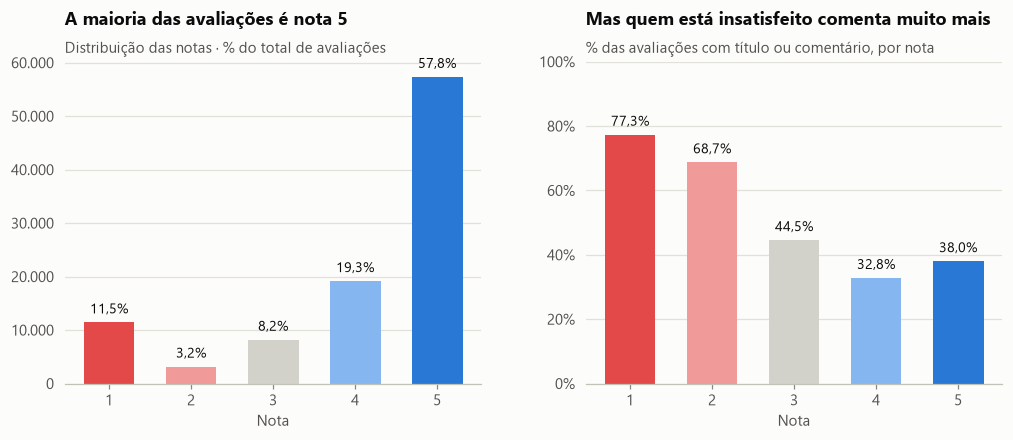

,avaliacoes,% com texto
review_score,,
1,11424,77.28
2,3151,68.71
3,8179,44.54
4,19142,32.78
5,57328,37.98


In [5]:
by_score = reviews.groupby("review_score").agg(avaliacoes=("review_id", "size"), com_texto=("has_text", "mean"))
total = by_score["avaliacoes"].sum()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"wspace": 0.25})

ax = axes[0]
bars = ax.bar(by_score.index, by_score["avaliacoes"], width=0.62,
              color=[SCORE_COLORS[s] for s in by_score.index])
label_bars(ax, bars, [pct(v, total) for v in by_score["avaliacoes"]])
ax.set_title("A maioria das avaliações é nota 5")
subtitle(ax, "Distribuição das notas · % do total de avaliações")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: num(v)))
ax.set_xlabel("Nota")

ax = axes[1]
bars = ax.bar(by_score.index, by_score["com_texto"], width=0.62,
              color=[SCORE_COLORS[s] for s in by_score.index])
label_bars(ax, bars, [pct(v, 1) for v in by_score["com_texto"]])
ax.set_title("Mas quem está insatisfeito comenta muito mais")
subtitle(ax, "% das avaliações com título ou comentário, por nota")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_ylim(0, 1)
ax.set_xlabel("Nota")
plt.show()

by_score.assign(com_texto=by_score["com_texto"] * 100).rename(columns={"com_texto": "% com texto"})

In [6]:
text_by_score = reviews[reviews["has_text"]].groupby("review_score").size()
display(Markdown(
    f"**{num(reviews['has_text'].sum())} avaliações têm algum texto** "
    f"({pct(reviews['has_text'].sum(), len(reviews))} da base). Dessas, "
    f"**{pct(text_by_score.loc[[1, 2]].sum(), text_by_score.sum())} são negativas (nota 1–2)**, "
    f"contra {pct(by_score.loc[[1, 2], 'avaliacoes'].sum(), total)} na base completa."
))

**42.687 avaliações têm algum texto** (43,0% da base). Dessas, **25,8% são negativas (nota 1–2)**, contra 14,7% na base completa.

**Leitura**
- **Avaliações negativas são sobrerrepresentadas entre as que têm texto.** Cerca de 3 em cada 4 notas 1 comentam, contra pouco mais de 1 em cada 3 notas 5. Para um projeto de *Voice of Customer*, isso é positivo: os motivos de insatisfação estão bem documentados.
- **O título carrega informação própria.** Cerca de 1.700 avaliações têm *só* título. Usar apenas o campo de comentário descartaria essas avaliações.

> **Implicação para o projeto**
> - O documento do RAG será **título + comentário**, e uma avaliação entra na base se tiver qualquer um dos dois.
> - Avaliações sem texto ficam fora da busca semântica, mas continuam úteis para estatísticas de nota.
> - Como os negativos estão sobrerrepresentados na base de texto, **frequências calculadas nos comentários não são proporções da base inteira**. As respostas não devem fazer essa extrapolação.

## 3. Qual o tamanho dos comentários?

O tamanho dos textos define se é preciso dividir os documentos (*chunking*). O modelo de embeddings escolhido, `multilingual-e5-base`, processa até 512 *tokens* por texto.

In [7]:
msg = reviews["review_comment_message"].dropna().str.strip()
msg = msg[msg != ""]
chars = msg.str.len()
words = msg.str.split().str.len()

pd.DataFrame({"caracteres": chars.describe(percentiles=[.1, .25, .5, .75, .9, .99]),
              "palavras": words.describe(percentiles=[.1, .25, .5, .75, .9, .99])}).T

,count,mean,std,min,10%,25%,50%,75%,90%,99%,max
caracteres,"40,950.00",68.40,53.83,1.00,12.00,28.00,53.00,94.00,160.00,200.00,208.00
palavras,"40,950.00",11.69,9.55,1.00,2.00,4.00,9.00,16.00,28.00,37.00,45.00


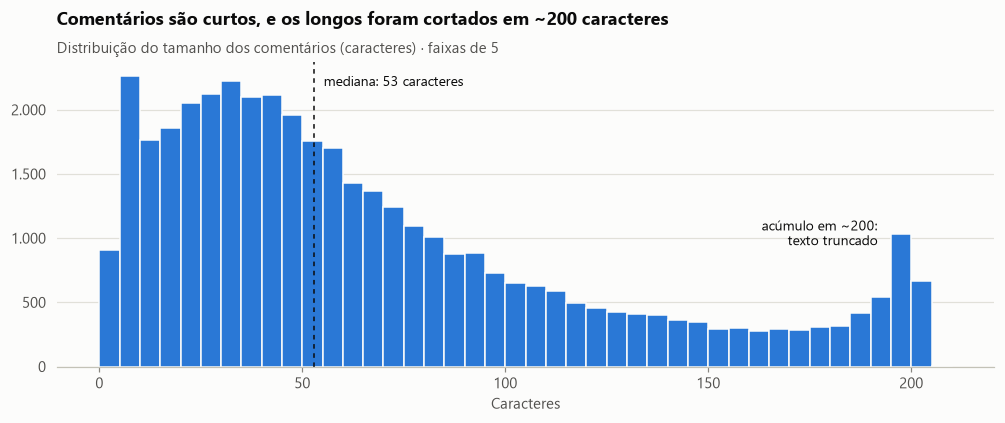

In [8]:
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.hist(chars, bins=range(0, 215, 5), color=PRIMARY, edgecolor=SURFACE, linewidth=1)
med = chars.median()
ax.axvline(med, color=INK, linewidth=1, linestyle=(0, (3, 3)))
ax.annotate(f"mediana: {med:.0f} caracteres", (med, ax.get_ylim()[1] * 0.92),
            xytext=(6, 0), textcoords="offset points", color=INK, fontsize=9)
ax.annotate("acúmulo em ~200:\ntexto truncado", (200, 1030), xytext=(-22, 0), textcoords="offset points",
            ha="right", va="center", color=INK, fontsize=9)
ax.set_title("Comentários são curtos, e os longos foram cortados em ~200 caracteres")
subtitle(ax, "Distribuição do tamanho dos comentários (caracteres) · faixas de 5")
ax.set_xlabel("Caracteres")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: num(v)))
plt.show()

In [9]:
ends_punct = msg.str[-1].str.contains(r"[.!?)]", regex=True)
display(Markdown(
    f"- Comentários com **exatamente 200 caracteres**: {num((chars == 200).sum())}, contra "
    f"{num((chars == 190).sum())} com 190.\n"
    f"- Terminam com pontuação final: **{pct(ends_punct[chars == 200].sum(), (chars == 200).sum())}** dos que "
    f"têm 200 caracteres, contra {pct(ends_punct[chars.between(100, 189)].sum(), chars.between(100, 189).sum())} "
    f"dos que têm entre 100 e 189.\n\nFinal de alguns comentários com 200 caracteres:"))
msg[chars == 200].str[-50:].sample(5, random_state=3).rename("últimos 50 caracteres").to_frame()

- Comentários com **exatamente 200 caracteres**: 597, contra 78 com 190.
- Terminam com pontuação final: **35,0%** dos que têm 200 caracteres, contra 75,5% dos que têm entre 100 e 189.

Final de alguns comentários com 200 caracteres:

,últimos 50 caracteres
32278,a resposta convincente!!! Aguardo contato urgente!
76068,não era..por isso eu quero devolvê-lo e o estorno
18441,0.Eu queria ter esperado mais e nao ter pago frete
3133,uras e ao invés venho a navalha queria uma explica
85516,"rio de atendimento é ridículo, só vagabundo pra ir"


**Leitura**
- Metade dos comentários tem até cerca de 53 caracteres, ou 9 palavras.
- **Há um acúmulo anormal em ~200 caracteres, com textos terminando no meio da palavra.** Os comentários foram truncados na origem, provavelmente por um limite do formulário. Não é possível recuperar o trecho perdido.
- Mesmo o maior comentário fica muito abaixo do limite de 512 *tokens* do modelo de embeddings.

> **Implicação para o projeto: sem *chunking*. Cada avaliação vira um documento.**
> - Dividir textos tão curtos só fragmentaria o sentido.
> - Agrupar várias avaliações num mesmo documento misturaria clientes, notas e pedidos diferentes e quebraria a rastreabilidade da evidência. O desafio exige justamente essa rastreabilidade.
> - O truncamento é uma **limitação da base**, a ser declarada na documentação: em relatos longos, o desfecho pode ter sido cortado.

## 4. Qualidade do texto

Avaliamos três aspectos:
- comentários curtos demais para servir de evidência;
- textos repetidos;
- ruídos de digitação.

In [10]:
def normalize_for_count(text: str) -> str:
    # Minúsculas, sem acentos e sem pontuação: só para COMPARAR textos, nunca para indexar.
    text = unicodedata.normalize("NFKD", text.lower())
    text = "".join(c for c in text if not unicodedata.combining(c))
    return re.sub(r"\s+", " ", re.sub(r"[^\w\s]", " ", text)).strip()

norm = msg.map(normalize_for_count)
counts = norm.value_counts()

display(Markdown(
    f"- Comentários com **até 3 caracteres**: {num((chars <= 3).sum())} · com **até 10**: {num((chars <= 10).sum())}\n"
    f"- Textos distintos (após normalizar): **{num(norm.nunique())} de {num(len(norm))}**\n"
    f"- {num((counts >= 2).sum())} textos aparecem mais de uma vez e somam "
    f"**{num(counts[counts >= 2].sum())} comentários** ({pct(counts[counts >= 2].sum(), len(norm))})"
))
counts.rename(index={"": "(só pontuação ou símbolos)"}).head(15).rename("ocorrências").to_frame()

- Comentários com **até 3 caracteres**: 809 · com **até 10**: 3.644
- Textos distintos (após normalizar): **33.481 de 40.950**
- 1.301 textos aparecem mais de uma vez e somam **8.770 comentários** (21,4%)

,ocorrências
review_comment_message,
muito bom,598
otimo,471
bom,369
recomendo,316
excelente,214
otimo produto,168
ok,158
tudo ok,131
(só pontuação ou símbolos),123


In [11]:
noise = {
    "quebra de linha": msg.str.contains(r"[\r\n]", regex=True),
    "pontuação repetida (!!!, ???, ...)": msg.map(lambda s: bool(re.search(r"([!?.])\1{2,}", s))),
    "todo em caixa alta": msg.map(lambda s: s.isupper()),
    "emoji": msg.map(lambda s: bool(re.search("[\U0001F300-\U0001FAFF☀-➿]", s))),
    "link (http)": msg.str.contains("http", regex=False),
}
pd.DataFrame({"comentários": {k: v.sum() for k, v in noise.items()},
              "%": {k: v.mean() * 100 for k, v in noise.items()}})

,comentários,%
quebra de linha,2710,6.62
"pontuação repetida (!!!, ???, ...)",2875,7.02
todo em caixa alta,1294,3.16
emoji,273,0.67
link (http),1,0.00


In [12]:
raw_lower = msg.str.lower().str.strip()
variants = raw_lower[raw_lower.isin(["ótimo", "otimo", "ótimo produto", "otimo produto"])].value_counts()
variants.rename("ocorrências").to_frame()

,ocorrências
review_comment_message,
otimo,227
ótimo,197
ótimo produto,81
otimo produto,37


### 4.1 Nomes de lojas anonimizados

Ao ler os comentários, aparecem palavras como "lannister" e "targaryen". A Olist anonimizou os nomes das empresas parceiras trocando-os por casas de *Game of Thrones*.

In [13]:
houses = ["lannister", "stark", "baratheon", "targaryen"]
lower = msg.str.lower()
mentions = pd.Series({h: lower.str.contains(rf"\b{h}\b", regex=True).sum() for h in houses}, name="comentários")
display(mentions.to_frame())
msg[lower.str.contains("lannister", regex=False)].sample(4, random_state=7).rename("exemplos").to_frame()

,comentários
lannister,1207
stark,305
baratheon,275
targaryen,272


,exemplos
32050,A loja lannister sempre atendeu as minhas expectativas no que diz respeito a qualidade do produto e prazo de entrega.
57848,"Comprei 5 itens, me chega 1 item que nem rastreio tem no site lannister e o vendedor vêm me perguntar se recebi o lo..."
69797,Sempre confiei nas redes lannister 👍🏻
28397,o protuto chegou corretamente. eu recomendo as lojas lannister. muito obrigado...


**Leitura**
- **Repetição é alta.** Cerca de 1 em cada 5 comentários é idêntico a outro: "muito bom", "recomendo", "ótimo"…
  - Na busca vetorial, isso faria os primeiros resultados de uma pergunta sobre elogios virem cheios de cópias do mesmo texto, sem acrescentar nenhuma evidência nova.
  - Essas repetições, porém, são **avaliações legítimas de clientes diferentes**: não são erro de dados.
- **Grafias variam.** "ótimo" e "otimo" aparecem quase na mesma proporção. Para comparar textos, a normalização precisa ignorar acentos.
- **O ruído é pequeno e superficial:** quebras de linha, pontuação repetida e caixa alta. Emojis e links são raros.
- **Lojas aparecem com nomes fictícios.** Cerca de 2 mil comentários citam uma "casa", e "lannister" é de longe a mais frequente.

> **Implicação para o projeto**
> - **Limpeza leve:** normalizar espaços e quebras de linha e reduzir pontuação repetida, **preservando acentos, emojis e caixa no texto indexado**. O modelo E5 foi treinado com texto natural, e "PÉSSIMO!!!" carrega intensidade que não deve ser apagada.
> - **Não remover duplicatas da base**, porque cada cópia é um cliente. A deduplicação será feita **na seleção das evidências**, comparando textos normalizados.
> - **Comentários sem conteúdo** (".", "ok", "10") serão marcados como de baixa informação, com um limiar a definir na etapa de preparo.
> - **Nomes anonimizados ficam no texto** (são parte do relato), mas o prompt do LLM vai explicar que são **pseudônimos de lojas**, para que a resposta não os apresente como empresas reais.

## 5. Como são os comentários reais?

Uma amostra aleatória (semente fixa) de comentários com mais de 40 caracteres, por nota, para dar uma ideia concreta do vocabulário dos clientes.

In [14]:
sample = (reviews[reviews["review_comment_message"].fillna("").str.len() > 40]
          .groupby("review_score", group_keys=False)
          .sample(3, random_state=42)[["review_score", "review_comment_title", "review_comment_message"]]
          .rename(columns={"review_score": "nota", "review_comment_title": "título",
                           "review_comment_message": "comentário"}))
sample.fillna("—").style.hide(axis="index").set_properties(**{"text-align": "left"})

nota,título,comentário
1,—,"O frete é caro e ainda se quiser tem q buscar no correio.Muito ruim.Ainda quer elogios,odiei."
1,—,"Essa foi a pior compra da minha vida, comprei dia 11/6/17 para receber dia 05/07/17 e até hoje não recebi e ninguém me ligou para dar uma satisfação. A pior comprar da minha vida."
1,—,"No sate falava que era Sony com case , chegou um que não é Sony e nem veio a Case, tomem cuidado com esse fornecedor promete uma coisa e manda outra."
2,—,Comprei um jogo de cama lençol e recebi um cobre leito
2,—,"Recebi o produto, na verdade comprei a case para um tablet 10.1 e não serviu, então as medidas dessa case não deve estar correta."
2,—,"ENTREGARAM UMA COQUETELEIRA DIFERENTE DO ANUNCIO, TUDO SUJA EMPOEIRADA E QUE VAZA UM MONTE DE WHEY DURANTE A MISTURA !"
3,—,"O produto foi entregue dentro do prazo, entretanto, não veio na embalagem original. Veio dentro de um saco plástico bem simples."
3,—,O produto esta em processo de devolução e foi entregue no lugar errado para qualquer pessoa. Logo o processo de devolução será demorado.
3,—,Ainda não recebi o meu produto. Quando receber posso recomendar a loja para todos!!!!
4,—,"Meu produto chegou, mas veio solto dentro da caixa e com amassamento na tampa do espremedor"


**Leitura:** nas notas baixas, os temas aparecem de forma explícita: produto não recebido, atraso, produto errado ou com defeito, falta de resposta do vendedor. Nas notas altas, o elogio costuma vir junto com a **entrega no prazo**. A logística aparece nos dois extremos, o que a seção 8 confirma com números.

## 6. Duplicatas e integridade

In [15]:
dup_review = reviews["review_id"].duplicated(keep=False)
integrity = pd.Series({
    "linhas em order_reviews": len(reviews),
    "review_id distintos": reviews["review_id"].nunique(),
    "linhas com review_id repetido": dup_review.sum(),
    "pares (review_id, order_id) repetidos": reviews.duplicated(["review_id", "order_id"]).sum(),
    "pedidos com mais de uma avaliação": (reviews["order_id"].value_counts() > 1).sum(),
    "avaliações sem pedido correspondente": (~reviews["order_id"].isin(orders["order_id"])).sum(),
    "pedidos sem itens": (~orders["order_id"].isin(items["order_id"])).sum(),
}, name="quantidade")
integrity.to_frame()

,quantidade
linhas em order_reviews,99224
review_id distintos,98410
linhas com review_id repetido,1603
"pares (review_id, order_id) repetidos",0
pedidos com mais de uma avaliação,547
avaliações sem pedido correspondente,0
pedidos sem itens,775


In [16]:
example_id = reviews.loc[dup_review & has_msg, "review_id"].iloc[0]
reviews.loc[reviews["review_id"] == example_id,
            ["review_id", "order_id", "review_score", "review_comment_message"]]

,review_id,order_id,review_score,review_comment_message
346,f4d74b17cd63ee35efa82cd2567de911,f269e83a82f64baa3de97c2ebf3358f6,3,"A embalagem deixou a desejar, por pouco o produto não foi danificado, a caixa estava toda amassada."
90298,f4d74b17cd63ee35efa82cd2567de911,a60c9bf6dcdd39e9f1c10ae5ad77c24d,3,"A embalagem deixou a desejar, por pouco o produto não foi danificado, a caixa estava toda amassada."


**Leitura**
- **O mesmo `review_id` aparece ligado a pedidos diferentes, com o mesmo texto.** É um comportamento conhecido da base Olist: uma única avaliação vale para vários pedidos do mesmo cliente.
  - Não há linhas inteiramente duplicadas.
  - Indexar cada linha criaria documentos repetidos com o mesmo identificador.
- **A integridade referencial está boa:** toda avaliação tem pedido correspondente.

> **Implicação para o projeto**
> - **Uma linha por `review_id`**, mantendo a primeira ocorrência. Assim o `review_id` vira o identificador único da evidência, que é o que o usuário vê ao rastrear uma resposta.
> - **Junção com outras tabelas sempre com `how="left"`.** Pedidos sem itens não podem derrubar avaliações.

## 7. Valores ausentes nas tabelas de apoio

In [17]:
missing = pd.Series({
    "produtos sem categoria": products["product_category_name"].isna().sum(),
    "categorias sem tradução": len(set(products["product_category_name"].dropna())
                                   - set(translation["product_category_name"])),
    "pedidos sem data de entrega ao cliente": orders["order_delivered_customer_date"].isna().sum(),
    "  ↳ dos quais com status 'delivered'": (orders["order_delivered_customer_date"].isna()
                                             & (orders["order_status"] == "delivered")).sum(),
}, name="quantidade")
display(missing.to_frame())
print("Categorias sem tradução:", sorted(set(products["product_category_name"].dropna())
                                         - set(translation["product_category_name"])))

,quantidade
produtos sem categoria,610
categorias sem tradução,2
pedidos sem data de entrega ao cliente,2965
↳ dos quais com status 'delivered',8


Categorias sem tradução: ['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos']


In [18]:
no_delivery = orders[orders["order_delivered_customer_date"].isna()]
no_delivery["order_status"].value_counts().rename("pedidos sem data de entrega").to_frame()

,pedidos sem data de entrega
order_status,
shipped,1107
canceled,619
unavailable,609
invoiced,314
processing,301
delivered,8
created,5
approved,2


**Leitura**
- Cerca de 2% dos produtos não têm categoria, e poucas categorias não têm tradução para o inglês.
- A falta de data de entrega **não é um erro: é informação.** Na maioria dos casos o pedido foi enviado mas não chegou, ou foi cancelado, ou ficou indisponível. Para Voice of Customer, "não recebi" é uma das reclamações mais importantes.
- Os poucos pedidos marcados como `delivered` sem data são uma inconsistência pontual da base.

> **Implicação para o projeto**
> - **Categoria ausente** vira `desconhecida`, em vez de descartar a avaliação. O comentário continua sendo evidência válida.
> - **Tradução ausente:** usamos o nome em português, que será o idioma principal da interface.
> - **Falta de data de entrega** vira um status explícito, `nao_entregue`. Não deve ser tratada como dado faltante.

## 8. Quais metadados explicam a insatisfação?

O desafio adicional sugere enriquecer o RAG com metadados. Antes de usá-los, verificamos **se eles de fato separam clientes satisfeitos e insatisfeitos**. Se um metadado não muda a nota, filtrar por ele não melhora a recuperação.

Usamos uma avaliação por `review_id` e calculamos o atraso como `data de entrega − data estimada`, em dias.

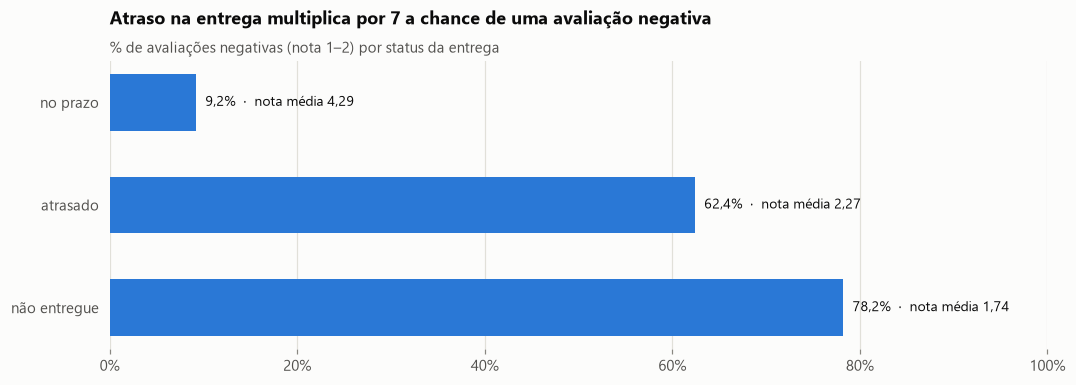

,avaliacoes,nota_media,pct_negativas
delivery_status,,,
no prazo,89245,4.29,9.22
atrasado,6362,2.27,62.42
não entregue,2803,1.74,78.24


In [19]:
o = orders.copy()
o["delay_days"] = (o["order_delivered_customer_date"].dt.normalize()
                   - o["order_estimated_delivery_date"].dt.normalize()).dt.days
o["delivery_status"] = "não entregue"
o.loc[o["delay_days"] <= 0, "delivery_status"] = "no prazo"
o.loc[o["delay_days"] > 0, "delivery_status"] = "atrasado"

rv = reviews.drop_duplicates("review_id").merge(o, on="order_id", how="left")
rv["negativa"] = rv["review_score"] <= 2

delivery = (rv.groupby("delivery_status")
            .agg(avaliacoes=("review_id", "size"), nota_media=("review_score", "mean"),
                 pct_negativas=("negativa", "mean"))
            .reindex(["no prazo", "atrasado", "não entregue"]))

fig, ax = plt.subplots(figsize=(11, 3.4))
bars = ax.barh(delivery.index[::-1], delivery["pct_negativas"][::-1], height=0.55, color=PRIMARY)
for bar, (status, row) in zip(bars, delivery[::-1].iterrows()):
    ax.annotate(f"{pct(row['pct_negativas'], 1)}  ·  nota média {row['nota_media']:.2f}".replace(".", ",", 1),
                (bar.get_width(), bar.get_y() + bar.get_height() / 2),
                xytext=(6, 0), textcoords="offset points", va="center", color=INK, fontsize=9)
ax.set_title("Atraso na entrega multiplica por 7 a chance de uma avaliação negativa")
subtitle(ax, "% de avaliações negativas (nota 1–2) por status da entrega")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_xlim(0, 1)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.spines["bottom"].set_visible(False)
plt.show()
delivery.assign(pct_negativas=delivery["pct_negativas"] * 100)

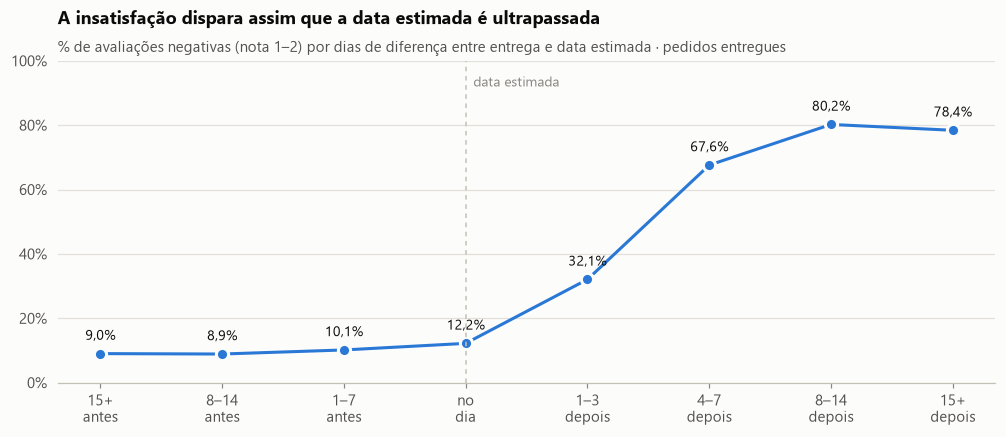

,avaliacoes,pct_negativas
faixa,,
15+ dias antes,34667,9.01
8–14 dias antes,36091,8.88
1–7 dias antes,17216,10.15
no dia,1271,12.20
1–3 dias depois,1843,32.07
4–7 dias depois,1746,67.58
8–14 dias depois,1440,80.21
15+ dias depois,1333,78.39


In [20]:
delivered = rv.dropna(subset=["delay_days"]).copy()
bins = [-1000, -15, -8, -1, 0, 3, 7, 14, 1000]
labels = ["15+ dias antes", "8–14 dias antes", "1–7 dias antes", "no dia", "1–3 dias depois",
          "4–7 dias depois", "8–14 dias depois", "15+ dias depois"]
delivered["faixa"] = pd.cut(delivered["delay_days"], bins=bins, labels=labels)
by_delay = delivered.groupby("faixa", observed=True).agg(
    avaliacoes=("review_id", "size"), pct_negativas=("negativa", "mean"))

fig, ax = plt.subplots(figsize=(11, 3.8))
x = range(len(by_delay))
ax.plot(x, by_delay["pct_negativas"], color=PRIMARY, linewidth=2, marker="o", markersize=8,
        markeredgecolor=SURFACE, markeredgewidth=2)
for i, v in zip(x, by_delay["pct_negativas"]):
    ax.annotate(pct(v, 1), (i, v), xytext=(0, 9), textcoords="offset points", ha="center",
                color=INK, fontsize=9)
ax.axvline(3, color=AXIS, linewidth=1, linestyle=(0, (3, 3)))
ax.annotate("data estimada", (3, 0.92), xytext=(5, 0), textcoords="offset points", color=MUTED, fontsize=9)
ax.set_xticks(list(x), [l.replace(" dias", "").replace(" ", "\n", 1) for l in labels])
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_title("A insatisfação dispara assim que a data estimada é ultrapassada")
subtitle(ax, "% de avaliações negativas (nota 1–2) por dias de diferença entre entrega e data estimada · pedidos entregues")
plt.show()
by_delay.assign(pct_negativas=by_delay["pct_negativas"] * 100)

avaliações
categoria           order_status            
(categoria ausente) delivered           1351
                    shipped               23
                    canceled              14
(pedido sem itens)  unavailable          584
                    canceled             135
                    created                3

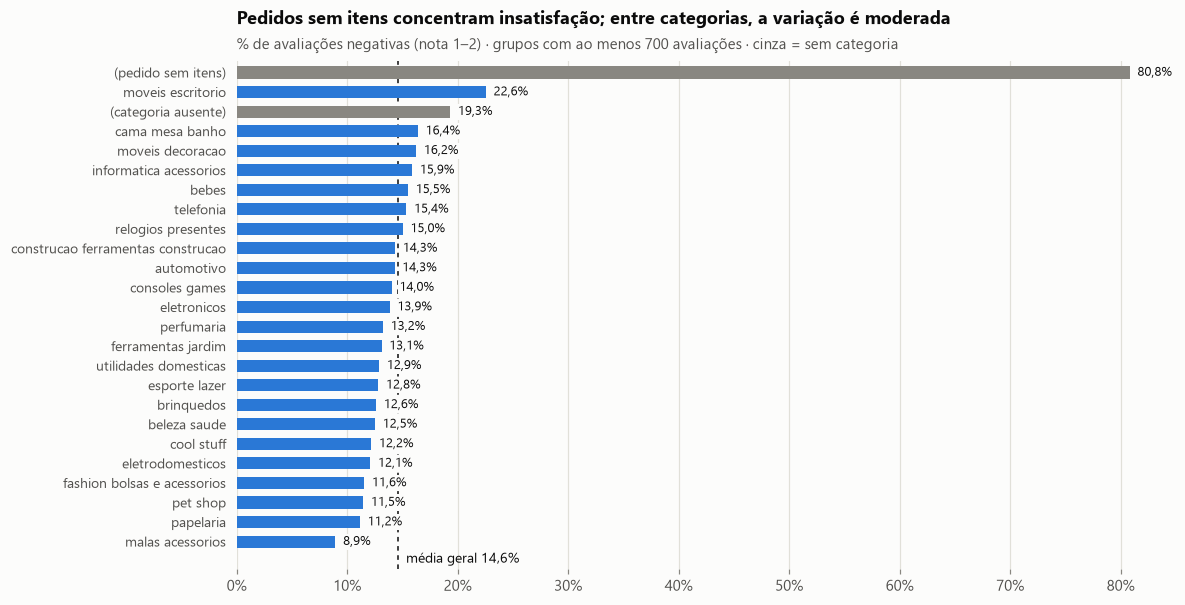

In [21]:
cat = (items.drop_duplicates("order_id")[["order_id", "product_id"]]
       .merge(products[["product_id", "product_category_name"]], on="product_id", how="left"))
rv_cat = rv.merge(cat, on="order_id", how="left")
rv_cat["categoria"] = rv_cat["product_category_name"].str.replace("_", " ")
# "Sem categoria" esconde dois casos distintos: pedidos sem nenhum item e produtos sem categoria.
no_items = ~rv_cat["order_id"].isin(items["order_id"])
rv_cat.loc[no_items, "categoria"] = "(pedido sem itens)"
rv_cat["categoria"] = rv_cat["categoria"].fillna("(categoria ausente)")

display(rv_cat[rv_cat["categoria"].str.startswith("(")]
        .groupby(["categoria", "order_status"]).size().rename("avaliações")
        .groupby(level=0, group_keys=False).nlargest(3).to_frame())

by_cat = (rv_cat.groupby("categoria")
          .agg(avaliacoes=("review_id", "size"), pct_negativas=("negativa", "mean"))
          .query("avaliacoes >= 700")
          .sort_values("pct_negativas"))
base_rate = rv["negativa"].mean()

fig, ax = plt.subplots(figsize=(11, 6))
colors = [MUTED if c.startswith("(") else PRIMARY for c in by_cat.index]
bars = ax.barh(by_cat.index, by_cat["pct_negativas"], height=0.62, color=colors, zorder=2)
ax.axvline(base_rate, color=INK, linewidth=1, linestyle=(0, (3, 3)), zorder=1)
for bar, v in zip(bars, by_cat["pct_negativas"]):
    ax.annotate(pct(v, 1), (bar.get_width(), bar.get_y() + bar.get_height() / 2),
                xytext=(5, 0), textcoords="offset points", va="center", color=INK, fontsize=8.5,
                bbox=LABEL_BOX, zorder=3)
ax.annotate(f"média geral {pct(base_rate, 1)}", (base_rate, -0.9), xytext=(5, 0),
            textcoords="offset points", va="center", color=INK, fontsize=9)
ax.set_ylim(-1.4, len(by_cat) - 0.4)
ax.set_title("Pedidos sem itens concentram insatisfação; entre categorias, a variação é moderada")
subtitle(ax, "% de avaliações negativas (nota 1–2) · grupos com ao menos 700 avaliações · cinza = sem categoria")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.spines["bottom"].set_visible(False)
ax.tick_params(axis="y", labelsize=9)
plt.show()

,avaliacoes,pct_negativas
meses de 2016 (fora do gráfico),,
2016-09,4,1.00
2016-10,318,0.29
2016-12,1,0.00


,avaliacoes,pct_negativas
após ago/2018 (fora do gráfico),,
2018-09,10,0.70
2018-10,2,1.00


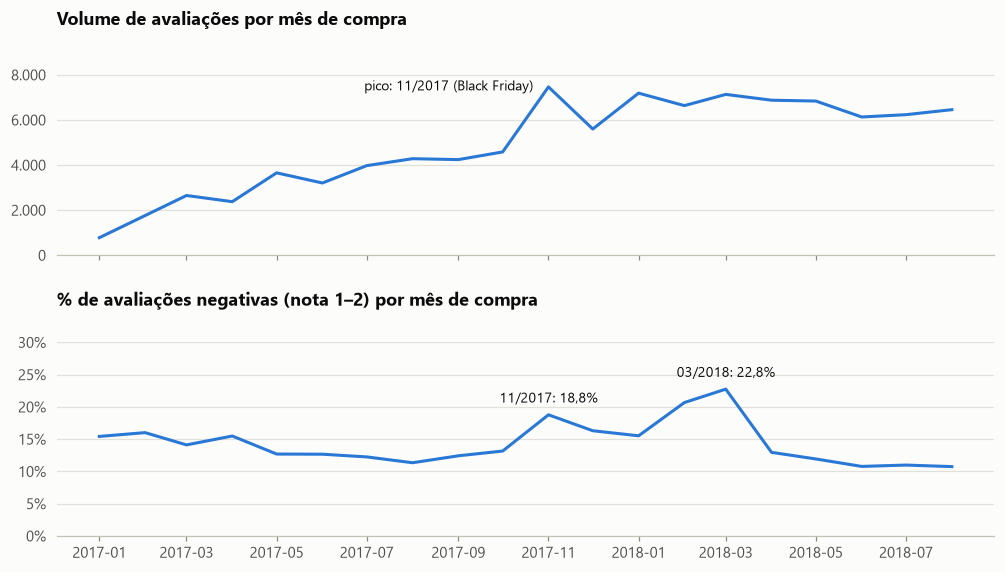

mes,2017-01,2017-02,2017-03,2017-04,2017-05,2017-06,2017-07,2017-08,2017-09,2017-10,2017-11,2017-12,2018-01,2018-02,2018-03,2018-04,2018-05,2018-06,2018-07,2018-08
avaliacoes,778.00,"1,761.00","2,650.00","2,376.00","3,655.00","3,205.00","3,975.00","4,283.00","4,242.00","4,582.00","7,467.00","5,599.00","7,190.00","6,637.00","7,134.00","6,877.00","6,839.00","6,133.00","6,235.00","6,457.00"
pct_negativas,15.42,16.01,14.11,15.49,12.69,12.67,12.25,11.35,12.42,13.16,18.78,16.31,15.52,20.67,22.75,12.96,11.93,10.78,10.99,10.75


In [22]:
rv["mes"] = rv["order_purchase_timestamp"].dt.to_period("M")
monthly = rv.groupby("mes").agg(avaliacoes=("review_id", "size"), pct_negativas=("negativa", "mean"))
# 2016 tem poucos pedidos e meses sem dados, e set–out/2018 são o corte da base: a série começa em 2017.
display(monthly[monthly.index < pd.Period("2017-01", "M")].rename_axis("meses de 2016 (fora do gráfico)"))
display(monthly[monthly.index > pd.Period("2018-08", "M")].rename_axis("após ago/2018 (fora do gráfico)"))
monthly = monthly[(monthly.index >= pd.Period("2017-01", "M")) & (monthly.index <= pd.Period("2018-08", "M"))]
x = monthly.index.to_timestamp()

fig, axes = plt.subplots(2, 1, figsize=(11, 5.6), sharex=True, gridspec_kw={"hspace": 0.45})
ax = axes[0]
ax.plot(x, monthly["avaliacoes"], color=PRIMARY, linewidth=2)
ax.set_title("Volume de avaliações por mês de compra")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: num(v)))
peak = monthly["avaliacoes"].idxmax()
ax.annotate(f"pico: {peak.strftime('%m/%Y')} (Black Friday)", (peak.to_timestamp(), monthly["avaliacoes"].max()),
            xytext=(-10, 0), textcoords="offset points", ha="right", va="center", color=INK, fontsize=9)
ax.set_ylim(0, monthly["avaliacoes"].max() * 1.15)

ax = axes[1]
ax.plot(x, monthly["pct_negativas"], color=PRIMARY, linewidth=2)
for p in [pd.Period("2017-11", "M"), pd.Period("2018-03", "M")]:
    v = monthly.loc[p, "pct_negativas"]
    ax.annotate(f"{p.strftime('%m/%Y')}: {pct(v, 1)}", (p.to_timestamp(), v), xytext=(0, 8),
                textcoords="offset points", ha="center", color=INK, fontsize=9)
ax.set_title("% de avaliações negativas (nota 1–2) por mês de compra")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_ylim(0, 0.3)
plt.show()
monthly.assign(pct_negativas=monthly["pct_negativas"] * 100).T

**Leitura**
- **A entrega é o metadado mais discriminante da base.**
  - Entregas no prazo têm cerca de 9% de avaliações negativas. Atrasadas, cerca de 62%. Não entregues, cerca de 78%.
  - A curva por dias de atraso mostra o efeito começando já no primeiro dia após a data estimada, o que sugere que o cliente julga pela **promessa** de prazo, e não pelo prazo absoluto.
- **"Sem categoria" escondia dois fenômenos diferentes.**
  - Os **pedidos sem nenhum item**, quase todos indisponíveis ou cancelados, têm a maior taxa de insatisfação da base. Nesses casos, o cliente nem chegou a receber um produto.
  - Já os produtos que apenas não têm categoria ficam próximos da média.
  - Tratar os dois como "desconhecida" misturaria esses perfis.
- **Entre as categorias reais, a variação é moderada.** O destaque negativo é móveis de escritório. A categoria é útil para perguntas segmentadas ("o que reclamam em móveis?").
- **O volume cresce ao longo de 2017**, com pico em novembro (Black Friday).
  - A taxa de negativas sobe nesse pico e volta a subir em fevereiro–março de 2018, o que é coerente com pressão logística em períodos de alta demanda.
  - 2016 e os meses após agosto de 2018 foram excluídos do gráfico por terem poucas avaliações.

> **Implicação para o projeto**
> - Os metadados que vão para o índice vetorial são: **status da entrega** (`no_prazo` / `atrasado` / `nao_entregue`), **dias de atraso**, **status do pedido**, **nota**, **sentimento derivado da nota** (negativo 1–2, neutro 3, positivo 4–5), **categoria** e **data**.
> - Pedidos sem itens recebem a categoria explícita `sem_itens`, separada de `desconhecida`.
> - Eles justificam filtros como "reclamações de clientes com entrega atrasada", que estreitam a busca para o subconjunto onde a evidência de fato está.
> - Esta análise é **descritiva**. Ela mostra associação, não causalidade.

## 9. Decisões para a preparação da base

| # | Achado | Decisão |
| --- | --- | --- |
| 1 | Só ~43% das avaliações têm texto; ~1,7 mil têm apenas título | Documento = **título + comentário**; entra quem tiver qualquer um dos dois |
| 2 | Negativas estão sobrerrepresentadas entre as que comentam | Respostas **não extrapolam** proporções dos comentários para a base inteira |
| 3 | Comentários curtos (mediana ~53 caracteres) e truncados em ~200 na origem | **Sem chunking**: uma avaliação = um documento. O truncamento é declarado como limitação |
| 4 | Ruído superficial (quebras de linha, pontuação repetida) | **Limpeza leve**, preservando acentos, caixa e emojis |
| 5 | Cerca de 1 em cada 5 comentários é cópia de outro | **Manter na base** (são clientes distintos); **deduplicar na seleção** das evidências |
| 6 | Grafias variam ("ótimo" × "otimo") | Comparação de textos com normalização **sem acentos** |
| 7 | Comentários sem conteúdo (".", "ok") | Marcar como baixa informação, com limiar a definir no preparo |
| 8 | Nomes de lojas anonimizados ("lannister", "stark"…) | Manter no texto; o prompt explica que são **pseudônimos de lojas** |
| 9 | `review_id` repetido em pedidos diferentes | **Uma linha por `review_id`**, que é o identificador da evidência |
| 10 | Pedidos sem itens (81% negativas) ≠ produtos sem categoria | Junções com `left join`; categorias explícitas **`sem_itens`** e **`desconhecida`** |
| 11 | Falta de data de entrega = pedido não entregue | Status explícito **`nao_entregue`** |
| 12 | Entrega é o metadado que mais separa satisfeitos de insatisfeitos | Metadados: **status e atraso da entrega**, status do pedido, nota, sentimento, categoria, data |

**Próxima etapa:** implementar essas decisões num módulo de preparo reprodutível (`src/preprocessing.py`), que gera a base de documentos do RAG.